# Challenge 4 – Orientation normalisation by registration

**Task.** Produce, for every part, an image of the part in a canonical pose:
- nuts: one of the sides completely parallel to the horizontal axis;
- screws: the longest axis vertical and the head on top.

**Requirements**
- Formulate it as an image registration problem: state the fixed and the moving image, the transformation model, the similarity measure and the optimiser
- Quantify the residual orientation error with a measurement independent of the estimator (e.g. Hough lines for the nut sides), and test the method on images rotated by known angles. Discuss the symmetries (60◦for a hexagon, 180◦for the head/tip ambiguity) and the dependence on the initial guess.
- Save every normalised part in outputs/ and show a mosaic of all of them.

**Checklist**

- Formulate it as an image registration problem:
    1. [x] State the fixed and the moving image
    2. [ ] State the transformation model
    3. [ ] State the similarity measure
    4. [ ] State the optimiser
- [ ] Recognise a side of the nut and rotate it to be horizontal
- [ ] Recognise the head of the screw and rotate it to be on top
- [ ] Quantify the residual orientation error with a measurement independent of the estimator (e.g. Hough lines for the nut sides)
- [ ] Test the method on images rotated by known angles. Discuss the symmetries (60° for a hexagon, 180° for the head/tip ambiguity)
- [ ] Test dependence on the initial guess.
- [ ] Save every normalised part in outputs/ and show a mosaic of all of them.

- [ ] {not requested} Compare the results with the head coordinates in the annotations.

## Setup of the environment


In [46]:
from pathlib import Path

import os
import cv2
import numpy as np
import math
from scipy import optimize

# Folders and constants
ANNOTATIONS_DIR = Path("annotations")

INPUT_DIR = Path("inputs")
VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

OUTPUT_DIR = Path("outputs")

C1_OUTPUT_DIR = OUTPUT_DIR / "challenge_1_results"

C2_OUTPUT_DIR = OUTPUT_DIR / "challenge_2_results"
TYPE_CSV = C2_OUTPUT_DIR / "rule_based_classification.results.csv"

C3_OUTPUT_DIR = OUTPUT_DIR / "challenge_3_results"

C4_OUTPUT_DIR = OUTPUT_DIR / "challenge_4_results"
CROPS_DIR = C4_OUTPUT_DIR / "crops"
TEMPLATES_DIR = C4_OUTPUT_DIR / "templates"
TEMPLATE_NUT = TEMPLATES_DIR / "fixed_nut.png"
TEMPLATE_SCREW = TEMPLATES_DIR / "fixed_screw.png"

NORMALIZED_DIR = C4_OUTPUT_DIR / "normalized"


C4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CROPS_DIR.mkdir(parents=True, exist_ok=True)
TEMPLATES_DIR.mkdir(parents=True, exist_ok=True)
NORMALIZED_DIR.mkdir(parents=True, exist_ok=True)

image_paths = sorted([p for p in INPUT_DIR.iterdir() if p.suffix.lower() in VALID_EXTS])

DEV_MODE = True       # Set to False when running tests
DEV_SAMPLE_SIZE = 10   # Quick iteration on just 10 images

if DEV_MODE:

    # Pick a spread of images that covers diferent setups
    #hard_stems = {"009","011","018","112","209","377","257","302","199","154"}
    dev_stems = {"026","027","028","029","040","041","042","061","063","119"}
    active_paths = [p for p in image_paths if any(p.stem.endswith(s) for s in dev_stems)]

    print(f"Running in DEV MODE on {len(active_paths)} images.")
else:
    active_paths = image_paths
    print(f"Running in FULL MODE on all {len(active_paths)} images.")

Running in DEV MODE on 10 images.


## 1. Formulate it as an image registration problem:
    - State the fixed and the moving image
    - State the transformation model
    - State the similarity measure
    - State the optimiser

### Fixed and moving image
The fixed image is the pose we want to achieve. The moving image is the screw in the original image with its original position.

For the fixed image, we create a stilized drawing of the screw and nut in the required pose.

Moving image: extracting and isolating each part from the original image.

→ Extracting the crop from the original image using the labels from Challenge 1.

→ Saving the extracted part as a moving image.

In [47]:
import os
import cv2
import numpy as np
from pathlib import Path

# Usiamo i tuoi percorsi con Path

def generate_fixed_images(size=(2000, 2000), output_dir=TEMPLATES_DIR):
    """
    Genera le Fixed Images (template canonici) corretti per Vite e Dado.
    - Vite: Asse centrale verticale, testa in alto.
    - Dado: Esagono regolare con il LATO IN BASSO PARALLELO ALL'ASSE X.
    """
    h, w = size
    cx, cy = w // 2, h // 2

    # ==========================================
    # 1. FIXED IMAGE PER LA VITE (Screw Template)
    # ==========================================
    screw_fixed = np.zeros((h, w), dtype=np.uint8)

    head_top_y = 30
    head_h = 20
    head_w = 140

    # Testa della vite (in alto)
    cv2.rectangle(screw_fixed,
                  (cx - head_w // 2, head_top_y),
                  (cx + head_w // 2, head_top_y + head_h),
                  255, -1)

    # Gambo (verticale al centro)
    stem_w = 20
    stem_bottom_y = h - 30
    cv2.rectangle(screw_fixed,
                  (cx - stem_w // 2, head_top_y + head_h),
                  (cx + stem_w // 2, stem_bottom_y),
                  255, -1)

    cv2.imwrite(str(TEMPLATE_SCREW), screw_fixed)
    print(f"✓ Fixed Image Vite salvata in: {screw_path}")

    # ==========================================
    # 2. FIXED IMAGE PER IL DADO (Nut Template - CORRETTO)
    # ==========================================
    nut_fixed = np.zeros((h, w), dtype=np.uint8)

    outer_radius = 80
    inner_radius = 35

    # Per avere i lati orizzontali in alto e in basso (paralleli all'asse X),
    # impostiamo gli angoli partendo da 0 (0, pi/3, 2pi/3, pi, 4pi/3, 5pi/3)
    angles = np.linspace(0, 2 * np.pi, 7)[:-1]

    vertices = []
    for angle in angles:
        vx = int(cx + outer_radius * np.cos(angle))
        vy = int(cy + outer_radius * np.sin(angle))
        vertices.append([vx, vy])

    pts = np.array(vertices, np.int32).reshape((-1, 1, 2))

    # Esagono pieno + foro centrale
    cv2.fillPoly(nut_fixed, [pts], 255)
    cv2.circle(nut_fixed, (cx, cy), inner_radius, 0, -1)

    cv2.imwrite(str(TEMPLATE_NUT), nut_fixed)
    print(f"✓ Fixed Image Dado (con lato orizzontale in basso) salvata in: {nut_path}")

    return screw_fixed, nut_fixed

# Esecuzione
screw_template, nut_template = generate_fixed_images()

✓ Fixed Image Vite salvata in: outputs/challenge_4_results/crops/crop_screws_026_part_03.png
✓ Fixed Image Dado (con lato orizzontale in basso) salvata in: outputs/challenge_4_results/crops/crop_screws_026_part_02.png


In [48]:
def extract_crops_from_c1_labels(
    image_path: Path,
    c1_dir: Path = C1_OUTPUT_DIR,
    output_dir: Path = CROPS_DIR,
    padding: int = 10
):
    """
    Legge l'immagine originale da INPUT_DIR e la corrisponde maschera segmentata
    dal Challenge 1 (<stem>_labels_image.png), estraendo ciascun componente come PNG RGBA trasparente.
    """
    stem = image_path.stem

    # 1. Trova l'immagine con le etichette salvata nel Challenge 1
    # Convenzione: nomeoriginale_labels_image.png
    label_path = c1_dir / f"{stem}_label_image.png"

    if not label_path.exists():
        print(f"⚠️ Maschera non trovata per {stem}: {label_path}")
        return []

    # 2. Carica l'immagine a colori originale e la mappa delle etichette (grayscale/16-bit)
    img_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    labels_img = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)

    if img_bgr is None or labels_img is None:
        print(f"Errore nel caricamento delle immagini per lo stem: {stem}")
        return []

    # 3. Trova tutti gli ID delle parti (ignoriamo 0 che è lo sfondo)
    unique_part_ids = np.unique(labels_img)
    unique_part_ids = unique_part_ids[unique_part_ids != 0]

    h_img, w_img = img_bgr.shape[:2]
    extracted_crops = []

    for part_id in unique_part_ids:
        # Crea la maschera binaria booleana per questo specifico part_id
        part_mask = (labels_img == part_id).astype(np.uint8) * 255

        # Trova le coordinate (Bounding Box) del pezzo
        y_indices, x_indices = np.where(part_mask > 0)
        if len(y_indices) == 0:
            continue

        x_min, x_max = np.min(x_indices), np.max(x_indices)
        y_min, y_max = np.min(y_indices), np.max(y_indices)

        # Applicazione padding entro i confini dell'immagine
        x1 = max(0, x_min - padding)
        y1 = max(0, y_min - padding)
        x2 = min(w_img, x_max + 1 + padding)
        y2 = min(h_img, y_max + 1 + padding)

        # 4. Ritaglio dell'immagine BGR e della maschera per questo pezzo
        crop_bgr = img_bgr[y1:y2, x1:x2]
        crop_mask = part_mask[y1:y2, x1:x2]

        # 5. Creazione dell'immagine RGBA (4 canali)
        b, g, r = cv2.split(crop_bgr)

        # Rendiamo nero lo sfondo sotto la trasparenza
        b = cv2.bitwise_and(b, crop_mask)
        g = cv2.bitwise_and(g, crop_mask)
        r = cv2.bitwise_and(r, crop_mask)

        # Canale Alfa: opaco (255) sul pezzo, trasparente (0) sullo sfondo
        a = crop_mask

        crop_rgba = cv2.merge([b, g, r, a])

        # 6. Salvataggio con la convenzione di nome per il Challenge 4
        # Formato: crop_<stem>_part_<part_id>.png
        crop_filename = output_dir / f"crop_{stem}_part_{int(part_id):02d}.png"
        cv2.imwrite(str(crop_filename), crop_rgba)

        extracted_crops.append(crop_rgba)

    return extracted_crops


# Loop di esecuzione per tutte le immagini attive
total_crops = 0
for path in active_paths:
    crops = extract_crops_from_c1_labels(path)
    total_crops += len(crops)
    print(f"Estratti {len(crops)} crop trasparenti per {path.name}")

print(f"\n✓ Estrazione completata! Salvati {total_crops} crop RGBA in: {CROPS_DIR}")

Estratti 8 crop trasparenti per screws_026.png
Estratti 8 crop trasparenti per screws_027.png
Estratti 8 crop trasparenti per screws_028.png
Estratti 8 crop trasparenti per screws_029.png
Estratti 10 crop trasparenti per screws_040.png
Estratti 9 crop trasparenti per screws_041.png
Estratti 10 crop trasparenti per screws_042.png
Estratti 8 crop trasparenti per screws_061.png
Estratti 8 crop trasparenti per screws_063.png
Estratti 9 crop trasparenti per screws_119.png

✓ Estrazione completata! Salvati 86 crop RGBA in: outputs/challenge_4_results/crops


### 3. Initial guess with PCA

_{IDEA}: try to use point to an edge instead of a side of the nut._


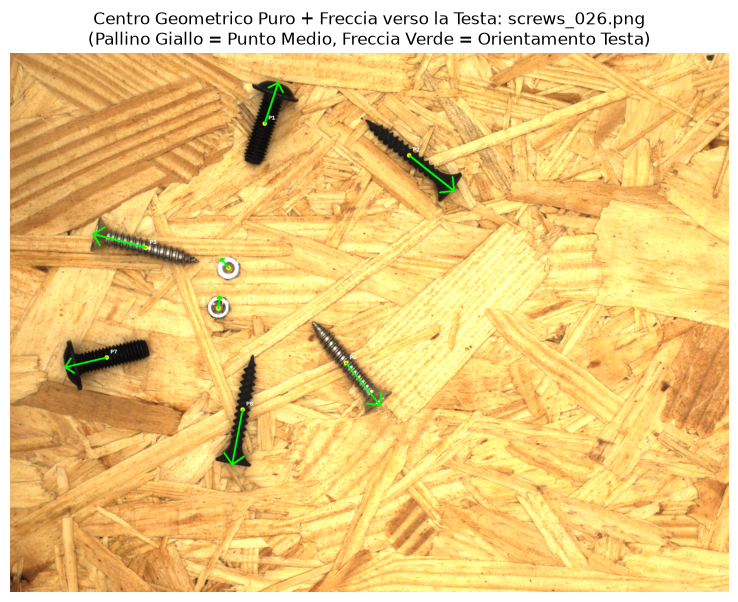

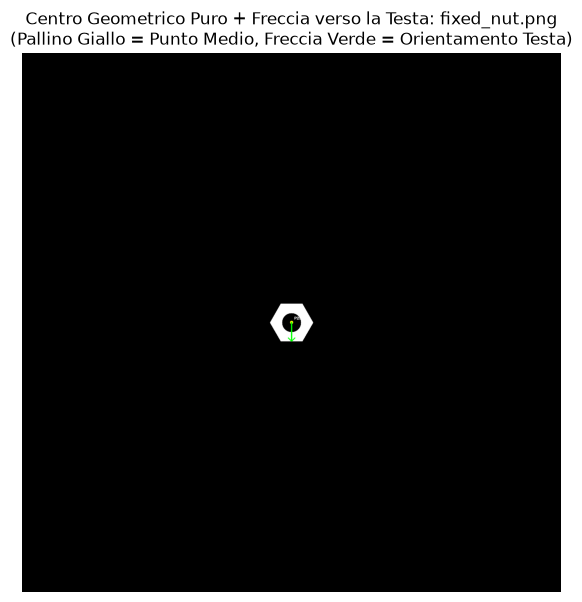

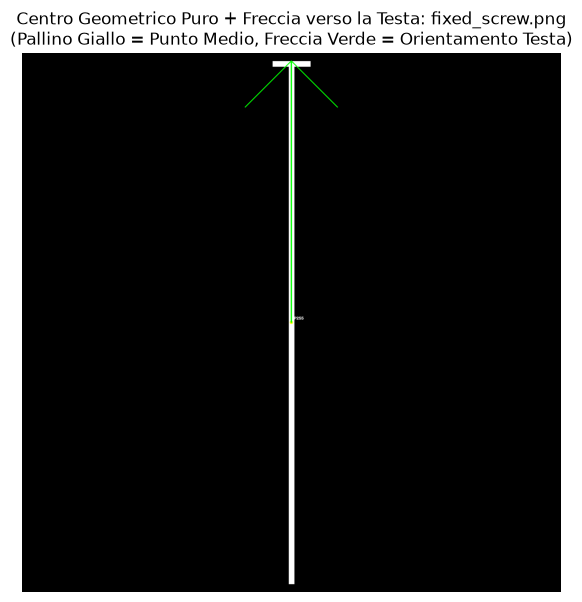

In [56]:
%matplotlib inline

import math
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

INPUT_DIR = Path("inputs")
C1_OUTPUT_DIR = Path("outputs/challenge_1_results")
C4_OUTPUT_DIR = Path("outputs/challenge_4_results")
C4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_paths = active_paths

def visualize_pca_pure_midpoint_with_head(image_path: Path, test_mode=False):

    stem = image_path.stem
    if test_mode:
        label_path = image_path
    else:
        label_path = C1_OUTPUT_DIR / f"{stem}_label_image.png"

    if not label_path.exists():
        print(f"⚠️ Maschera non trovata in {label_path}")
        return

    img_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    labels_img = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)

    if img_bgr is None or labels_img is None:
        return

    canvas = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    unique_parts = np.unique(labels_img)
    unique_parts = unique_parts[unique_parts != 0]

    for part_id in unique_parts:
        mask = (labels_img == part_id).astype(np.uint8) * 255
        y_idx, x_idx = np.where(mask > 0)

        if len(y_idx) < 10:
            continue

        # 1. PCA base
        pts = np.column_stack((x_idx, y_idx)).astype(np.float32)
        mean, eigenvectors, _ = cv2.PCACompute2(pts, mean=None)

        cx, cy = mean[0]        # Baricentro usato solo per originare le proiezioni
        v0 = eigenvectors[0]    # Vettore direzione asse PCA

        # 2. Proiezione dei punti sull'asse per trovare i due estremi p_min e p_max
        dx = x_idx - cx
        dy = y_idx - cy
        projections = dx * v0[0] + dy * v0[1]

        p_min = np.min(projections)
        p_max = np.max(projections)

        # 3. PUNTO CENTRALE GEOMETRICO PURO: (p_min + p_max) / 2
        mid_offset = (p_min + p_max) / 2.0
        mid_x = cx + v0[0] * mid_offset
        mid_y = cy + v0[1] * mid_offset

        # 4. DETERMINAZIONE DELLA TESTA (Analisi di massa ai due estremi)
        head_region = projections > (p_max - (p_max - p_min) * 0.25)
        tail_region = projections < (p_min + (p_max - p_min) * 0.25)

        # Se la parte inferiore (tail) ha più pixel della parte superiore (head), invertiamo il vettore
        if np.sum(tail_region) > np.sum(head_region):
            v0 = -v0

        # 5. DISEGNO
        length = (p_max - p_min) / 2.0
        x_end = int(mid_x + v0[0] * length)
        y_end = int(mid_y + v0[1] * length)

        # Punto Medio Geometrico (Pallino Giallo)
        cv2.circle(canvas, (int(mid_x), int(mid_y)), 6, (255, 255, 0), -1)

        # Freccia PCA dal Punto Medio verso la Testa (Freccia Verde)
        cv2.arrowedLine(canvas, (int(mid_x), int(mid_y)), (x_end, y_end), (0, 255, 0), 3, tipLength=0.25)

        # Etichetta Pezzo
        cv2.putText(canvas, f"P{part_id}", (int(mid_x) + 10, int(mid_y) - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

    # Salvataggio anteprima su disco
    out_preview_path = C4_OUTPUT_DIR / f"pure_midpoint_head_preview_{stem}.png"
    cv2.imwrite(str(out_preview_path), cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))

    # Visualizzazione
    plt.figure(figsize=(10, 7))
    plt.imshow(canvas)
    plt.title(f"Centro Geometrico Puro + Freccia verso la Testa: {image_path.name}\n(Pallino Giallo = Punto Medio, Freccia Verde = Orientamento Testa)")
    plt.axis("off")
    plt.show()

# Esecuzione sulla prima immagine
if len(image_paths) > 0:

    visualize_pca_pure_midpoint_with_head(image_paths[0])
visualize_pca_pure_midpoint_with_head(TEMPLATE_NUT, test_mode=True)
visualize_pca_pure_midpoint_with_head(TEMPLATE_SCREW, test_mode=True)

###

In [59]:
import math
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

INPUT_DIR = Path("inputs")
C1_OUTPUT_DIR = Path("outputs/challenge_1_results")
C4_OUTPUT_DIR = Path("outputs/challenge_4_results")
C4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_paths = active_paths


# --- 1. FUNZIONE DI CALCOLO PCA ED ESTRAZIONE DATAFRAME ---
def analyze_image_pca(image_path: Path, test_mode: bool = False, padding: int = 10) -> pd.DataFrame:
    """
    Analizza l'immagine e calcola le metriche PCA per ogni componente,
    restituendo un DataFrame con tutte le informazioni raccolte.
    """
    stem = image_path.stem
    if test_mode:
        label_path = image_path
    else:
        label_path = C1_OUTPUT_DIR / f"{stem}_label_image.png"

    if not label_path.exists():
        print(f"⚠️ Maschera non trovata in {label_path}")
        return pd.DataFrame()

    img_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    labels_img = cv2.imread(str(label_path), cv2.IMREAD_UNCHANGED)

    if img_bgr is None or labels_img is None:
        return pd.DataFrame()

    unique_parts = np.unique(labels_img)
    unique_parts = unique_parts[unique_parts != 0]

    parts_data = []

    for part_id in unique_parts:
        mask = (labels_img == part_id).astype(np.uint8) * 255
        y_idx, x_idx = np.where(mask > 0)

        if len(y_idx) < 10:
            continue

        # 1. PCA base
        pts = np.column_stack((x_idx, y_idx)).astype(np.float32)
        mean, eigenvectors, _ = cv2.PCACompute2(pts, mean=None)

        cx, cy = mean[0]
        v0 = eigenvectors[0]

        # 2. Proiezioni ed Estremi
        dx = x_idx - cx
        dy = y_idx - cy
        projections = dx * v0[0] + dy * v0[1]

        p_min = float(np.min(projections))
        p_max = float(np.max(projections))
        half_len = (p_max - p_min) / 2.0

        # 3. Punto Medio Geometrico Puro
        mid_offset = (p_min + p_max) / 2.0
        global_mid_x = float(cx + v0[0] * mid_offset)
        global_mid_y = float(cy + v0[1] * mid_offset)

        # 4. Determinazione della Testa (Analisi Massa)
        head_region = projections > (p_max - (p_max - p_min) * 0.25)
        tail_region = projections < (p_min + (p_max - p_min) * 0.25)

        if np.sum(tail_region) > np.sum(head_region):
            v0 = -v0

        # Angoli e Punti finali
        vec_angle_deg = math.degrees(math.atan2(v0[1], v0[0]))
        global_head_x = global_mid_x + v0[0] * half_len
        global_head_y = global_mid_y + v0[1] * half_len

        # Bounding Box per i crop futuri
        x1 = max(0, int(np.min(x_idx)) - padding)
        y1 = max(0, int(np.min(y_idx)) - padding)

        parts_data.append({
            "image": stem,
            "part_id": int(part_id),
            "global_mid_x": global_mid_x,
            "global_mid_y": global_mid_y,
            "global_head_x": global_head_x,
            "global_head_y": global_head_y,
            "vec_x": float(v0[0]),
            "vec_y": float(v0[1]),
            "vec_angle_deg": vec_angle_deg,
            "half_len": half_len,
            "crop_x1": x1,
            "crop_y1": y1,
            "local_mid_x": global_mid_x - x1,
            "local_mid_y": global_mid_y - y1,
            "local_head_x": global_head_x - x1,
            "local_head_y": global_head_y - y1
        })

    return pd.DataFrame(parts_data)


# --- 2. FUNZIONE DI VISUALIZZAZIONE DAI DATI DEL DATAFRAME ---
def visualize_pca_pure_midpoint_with_head(image_path: Path, df_parts: pd.DataFrame = None, test_mode: bool = False, cropped: bool = False):
    """
    Visualizza la freccia e il punto medio leggendo i dati direttamente dal DataFrame.
    Se df_parts è None, lo calcola automaticamente al momento.
    """
    stem = image_path.stem

    # Se df_parts è None, lo calcola al volo
    if df_parts is None:
        df_parts = analyze_image_pca(image_path, test_mode=test_mode)

    if df_parts.empty:
        print(f"⚠️ Nessun dato trovato nel DataFrame.")
        return

    # Se image_path è direttamente il path di un crop (es. crop_026_part_01)
    if cropped and "part_" in stem:
        parts = stem.split("_")
        try:
            part_id = int(parts[-1])
            orig_stem = parts[1] if len(parts) >= 3 else parts[0]
            df_img = df_parts[(df_parts["image"] == orig_stem) & (df_parts["part_id"] == part_id)]
        except ValueError:
            df_img = df_parts[df_parts["image"] == stem]
    else:
        df_img = df_parts[df_parts["image"] == stem]

    if df_img.empty:
        print(f"⚠️ Nessuna voce trovata nel DataFrame per {stem}")
        return

    if not cropped:
        # ==========================================
        # 1. IMMAGINE INTERA (Coordinate Globali)
        # ==========================================
        img_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if img_bgr is None:
            print(f"⚠️ Impossibile caricare l'immagine: {image_path}")
            return

        canvas = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        for _, row in df_img.iterrows():
            part_id = int(row["part_id"])
            mid_x = row["global_mid_x"]
            mid_y = row["global_mid_y"]
            x_end = row["global_head_x"]
            y_end = row["global_head_y"]

            # Punto Medio Geometrico (Pallino Giallo)
            cv2.circle(canvas, (int(mid_x), int(mid_y)), 6, (255, 255, 0), -1)
            # Freccia PCA (Verde)
            cv2.arrowedLine(canvas, (int(mid_x), int(mid_y)), (int(x_end), int(y_end)), (0, 255, 0), 3, tipLength=0.25)
            # Etichetta
            cv2.putText(canvas, f"P{part_id}", (int(mid_x) + 10, int(mid_y) - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

        out_preview_path = C4_OUTPUT_DIR / f"pure_midpoint_head_preview_{stem}.png"
        cv2.imwrite(str(out_preview_path), cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))

        plt.figure(figsize=(10, 7))
        plt.imshow(canvas)
        plt.title(f"Centro Geometrico Globale: {image_path.name}")
        plt.axis("off")
        plt.show()

    else:
        # ==========================================
        # 2. VISUALIZZAZIONE CROP (Coordinate Locali)
        # ==========================================
        for _, row in df_img.iterrows():
            part_id = int(row["part_id"])
            orig_stem = row["image"]

            # Ricerca flessibile del file del crop in CROPS_DIR
            crop_path = CROPS_DIR / f"crop_{orig_stem}_part_{part_id:02d}.png"
            if not crop_path.exists():
                crop_path = CROPS_DIR / f"crop_{orig_stem}_part_{part_id}.png"
            if not crop_path.exists():
                crop_path = CROPS_DIR / f"crops_{orig_stem}_part_{part_id:02d}.png"

            if not crop_path.exists():
                print(f"⚠️ File crop non trovato per {orig_stem} part {part_id} in {CROPS_DIR}")
                continue

            crop_img = cv2.imread(str(crop_path), cv2.IMREAD_UNCHANGED)
            if crop_img is None:
                continue

            # Gestione trasparenza RGBA vs BGR
            if crop_img.ndim == 3 and crop_img.shape[2] == 4:
                canvas = cv2.cvtColor(crop_img, cv2.COLOR_BGRA2RGBA)
            else:
                canvas = cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB)

            # Uso delle coordinate locali dal DataFrame
            local_mid_x = row["local_mid_x"]
            local_mid_y = row["local_mid_y"]
            local_head_x = row["local_head_x"]
            local_head_y = row["local_head_y"]

            # Disegno su crop locale
            cv2.circle(canvas, (int(local_mid_x), int(local_mid_y)), 4, (255, 255, 0), -1)
            cv2.arrowedLine(canvas, (int(local_mid_x), int(local_mid_y)),
                            (int(local_head_x), int(local_head_y)), (0, 255, 0), 2, tipLength=0.25)
            cv2.putText(canvas, f"P{part_id}", (int(local_mid_x) + 5, int(local_mid_y) - 5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)

            out_preview_path = C4_OUTPUT_DIR / f"crop_preview_{orig_stem}_p{part_id:02d}.png"

            # Salvataggio anteprima crop
            if crop_img.ndim == 3 and crop_img.shape[2] == 4:
                cv2.imwrite(str(out_preview_path), cv2.cvtColor(canvas, cv2.COLOR_RGBA2BGRA))
            else:
                cv2.imwrite(str(out_preview_path), cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))

            plt.figure(figsize=(4, 4))
            plt.imshow(canvas)
            plt.title(f"Local Crop: {orig_stem} (Part {part_id})")
            plt.axis("off")
            plt.show()

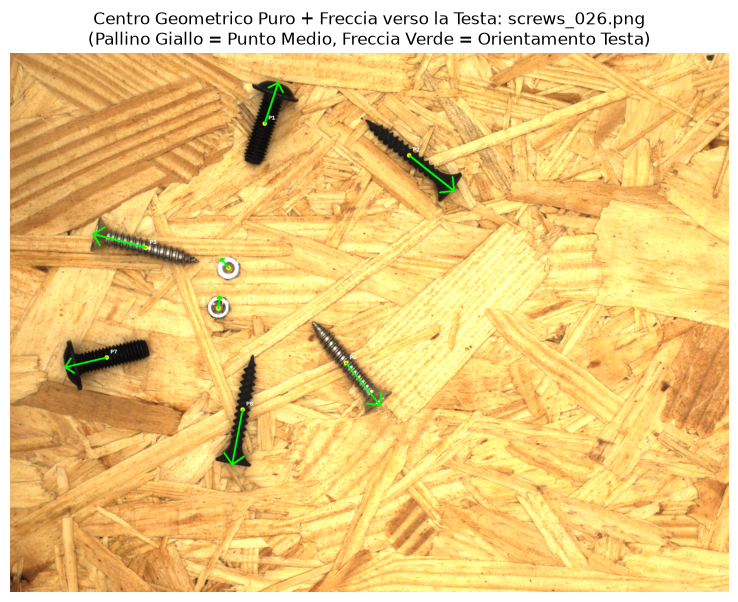

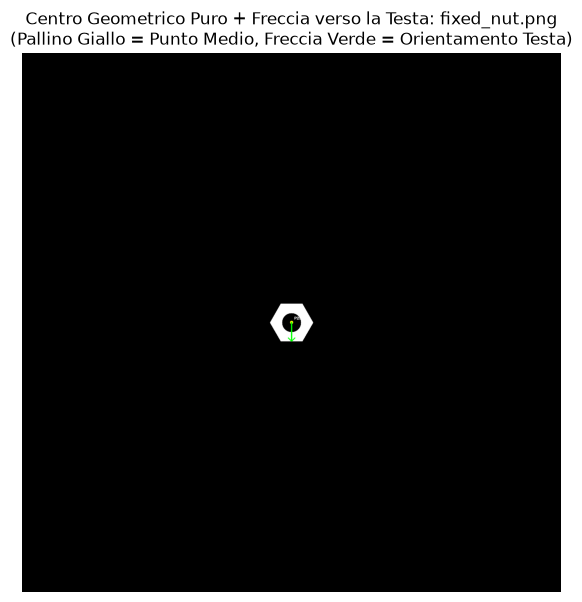

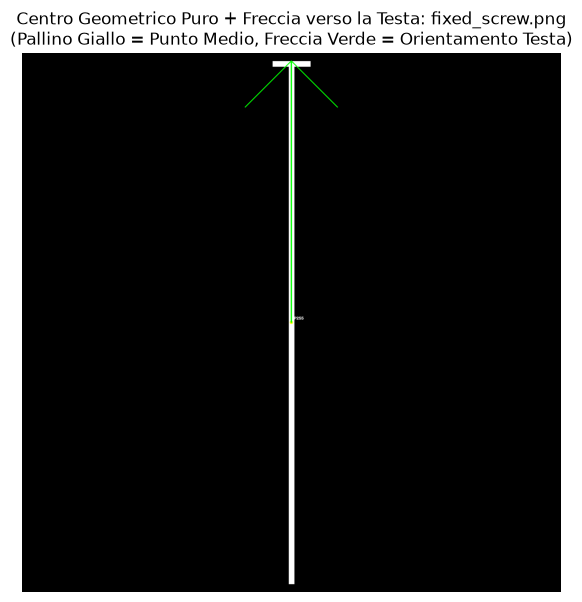

In [58]:
if len(image_paths) > 0:
    visualize_pca_pure_midpoint_with_head(image_paths[0])

visualize_pca_pure_midpoint_with_head(TEMPLATE_NUT, test_mode=True)
visualize_pca_pure_midpoint_with_head(TEMPLATE_SCREW, test_mode=True)

crops_paths = sorted([p for p in ])
visualize_pca_pure_midpoint_with_head(CROP)

# No need to check correctness of the DataFrame values here, as they are visualised in the image.